# Solution: Mission 03 — Fleet Demand Time Series Command

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

import polars as pl

def hourly_trips(month: str) -> pl.DataFrame:
    """Hourly trip counts of one month, with the cleaning rules of Lesson 08 (lazy Polars)."""
    start = pl.datetime(int(month[:4]), int(month[5:]), 1)
    dur = (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")).dt.total_seconds() / 60
    return (pl.scan_parquet(datasets.taxi(month))
              .filter(pl.col("tpep_pickup_datetime") >= start,
                      pl.col("tpep_pickup_datetime") < start.dt.offset_by("1mo"),
                      dur.is_between(1, 180), pl.col("fare_amount").is_between(3, 500))
              .group_by(pl.col("tpep_pickup_datetime").dt.truncate("1h").alias("hour"))
              .agg(trips=pl.len())
              .sort("hour")
              .collect())

hourly = pl.concat([hourly_trips("2024-01"), hourly_trips("2024-02")]).to_pandas().set_index("hour")["trips"]
print(len(hourly), "hours from", hourly.index.min(), "to", hourly.index.max())

1440 hours from 2024-01-01 00:00:00 to 2024-02-29 23:00:00


## Task 1: Complete, Time-Zone-Aware Index

In [2]:
full_index = pd.date_range("2024-01-01 00:00", "2024-02-29 23:00", freq="h")
missing = full_index.difference(hourly.index)
demand = hourly.reindex(full_index, fill_value=0)
demand.index = demand.index.tz_localize("America/New_York")
print(f"hours: {len(demand)} (missing hours filled with 0: {len(missing)}) | tz: {demand.index.tz}")

hours: 1440 (missing hours filled with 0: 0) | tz: America/New_York


## Task 2: Daily View

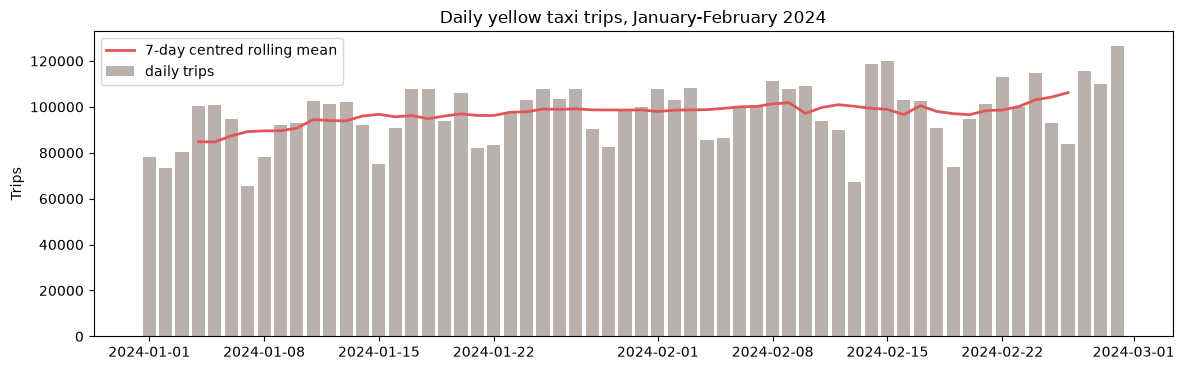

In [3]:
daily = demand.resample("D").sum()
roll = daily.rolling(7, center=True).mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(daily.index, daily, color="#BAB0AC", label="daily trips")
ax.plot(roll.index, roll, color="#E15759", lw=2, label="7-day centred rolling mean")
ax.set(title="Daily yellow taxi trips, January-February 2024", ylabel="Trips")
ax.legend()
plt.tight_layout()
plt.show()

## Task 3: Hour-of-Week Profile

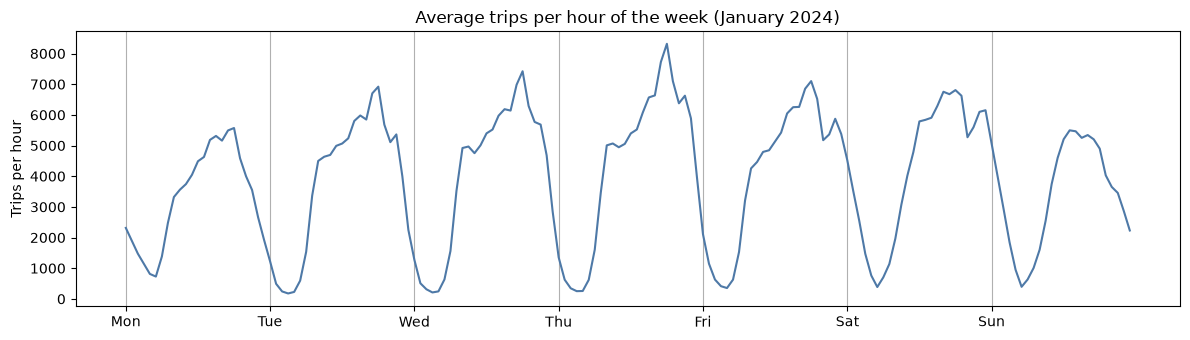

In [4]:
how = lambda idx: idx.day_of_week * 24 + idx.hour              # 0 = Monday 00:00 ... 167 = Sunday 23:00
jan = demand.loc["2024-01"]
profile = jan.groupby(how(jan.index)).mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(profile.index, profile.values, color="#4E79A7")
ax.set(xticks=range(0, 168, 24), xticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
       title="Average trips per hour of the week (January 2024)", ylabel="Trips per hour")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

## Task 4: Anomalous Days

In [5]:
# Note: a z-score against a centred 7-day window that contains the day itself can never exceed 6/sqrt(7) = 2.27,
# so a "z > 2.5" rule on such a window would never fire. Compare with the same weekday instead.
weekday_median = daily.groupby(daily.index.day_of_week).transform("median")
deviation = daily / weekday_median - 1
anomalies = pd.DataFrame({"trips": daily, "weekday_median": weekday_median.round(0),
                          "deviation_%": (100 * deviation).round(1)})[deviation.abs() > 0.15]
anomalies.index = anomalies.index.strftime("%a %Y-%m-%d")
anomalies

,trips,weekday_median,deviation_%
Tue 2024-01-02,73363,94878.0,-22.7
Wed 2024-01-03,80281,101324.0,-20.8
Sun 2024-01-07,65517,90520.0,-27.6
Tue 2024-02-13,67370,94878.0,-29.0
Wed 2024-02-14,118869,101324.0,17.3
Tue 2024-02-27,115461,94878.0,21.7
Thu 2024-02-29,126583,107943.0,17.3


Check each flagged day against the calendar and the news of New York. In this data, the days right after New Year (2 and 3 January) are well below their weekday median; 13 February, when a snowstorm hit the city and schools switched to remote learning, is the weakest weekday of the period; 14 February (Valentine's Day) is unusually busy. The other flags (for example 7 January and the busy last days of February) need a closer look at weather and events. Note that the public holidays (15 January and 19 February) were not flagged: on these Mondays, demand stayed within 15 % of the Monday median. A rule like this one is a screening tool: it finds candidates, a human explains them.

## Task 5: Two Forecasts for 19–29 February

                           MAE  MAPE_%
January profile          505.8    20.0
seasonal naive (t-168h)  615.2    18.6


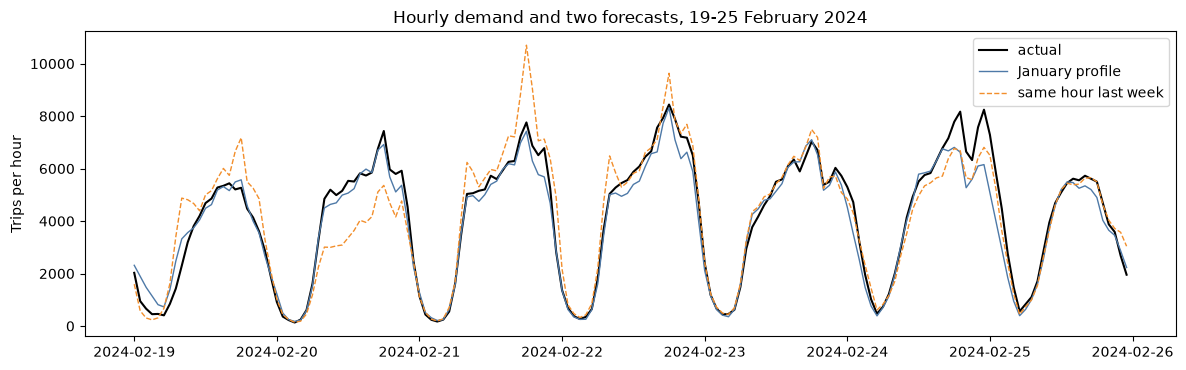

In [6]:
test = demand.loc["2024-02-19":"2024-02-29"]
f_profile = pd.Series(profile.loc[how(test.index)].to_numpy(), index=test.index)
f_naive = demand.shift(168).loc[test.index]                        # same hour one week earlier

def scores(actual, forecast):
    err = actual - forecast
    nz = actual > 0
    return {"MAE": err.abs().mean(), "MAPE_%": 100 * (err[nz].abs() / actual[nz]).mean()}

result = pd.DataFrame({"January profile": scores(test, f_profile), "seasonal naive (t-168h)": scores(test, f_naive)}).T.round(1)
print(result)

week = slice("2024-02-19", "2024-02-25")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(test.loc[week].index, test.loc[week], color="black", lw=1.5, label="actual")
ax.plot(f_profile.loc[week].index, f_profile.loc[week], color="#4E79A7", lw=1, label="January profile")
ax.plot(f_naive.loc[week].index, f_naive.loc[week], color="#F28E2B", lw=1, ls="--", label="same hour last week")
ax.set(title="Hourly demand and two forecasts, 19-25 February 2024", ylabel="Trips per hour")
ax.legend()
plt.tight_layout()
plt.show()

## Task 6: Recommendation

In [7]:
better = result["MAE"].idxmin()
print(f"Recommendation: use the '{better}' forecast for next week's driver schedule "
      f"(MAE {result.loc[better, 'MAE']:.0f} trips per hour, MAPE {result.loc[better, 'MAPE_%']:.0f} %).")
print("Next improvements: blend both methods, add a holiday calendar and a weather forecast as inputs, "
      "and evaluate on several weeks (rolling-origin backtest, M17).")

Recommendation: use the 'January profile' forecast for next week's driver schedule (MAE 506 trips per hour, MAPE 20 %).
Next improvements: blend both methods, add a holiday calendar and a weather forecast as inputs, and evaluate on several weeks (rolling-origin backtest, M17).


A seasonal naive forecast reacts to recent changes (for example a holiday the week before), while a monthly profile is smoother but can miss a trend. Neither method knows about holidays or snow; adding such inputs is the topic of forecasting models in M17.